# Baked floor-posture dataset

Loads the Hugging Face dataset written by `python -m data.extract` and plots a few things from it.
Run `python -m data.extract` first if `data/processed/floor_posture` doesn't exist.

The data contains identifiable camera frames: keep it local.

In [20]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_from_disk

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
ds = load_from_disk(repo / "data/processed/floor_posture")
ds

Dataset({
    features: ['recording', 'room', 'frame_idx', 'timestamp', 'radar_frame_num', 'image', 'radar_payload', 'heatmap', 'heatmap_ok', 'pointcloud', 'n_points', 'n_tracks', 'n_heights', 'cfg_file', 'range_resolution_m', 'range_max_m', 'doppler_resolution_m_s', 'max_velocity_m_s', 'num_range_bins', 'num_doppler_bins', 'num_tx', 'num_rx', 'label_activity', 'label_activity_confidence', 'label_fall', 'label_fall_confidence', 'label_orientation', 'label_orientation_confidence', 'label_pose', 'label_pose_confidence', 'label_presence', 'label_presence_confidence', 'label_state_labels', 'label_state_labels_confidence', 'label_2_classes', 'label_2_classes_confidence', 'label_3_classes', 'label_3_classes_confidence', 'label_labels', 'label_labels_confidence', 'label_labels_no_movements', 'label_labels_no_movements_confidence', 'person', 'person_present'],
    num_rows: 33200
})

## Columns

Everything is stored, so pick what you need. `select_columns` is cheap because the data is memory-mapped;
the heavy columns (`image`, `radar_payload`, `heatmap`, `pointcloud`) are only read when accessed.

In [21]:
heavy = ["image", "radar_payload", "heatmap", "pointcloud"]
meta = ds.remove_columns(heavy).to_pandas()
meta.head(3).T

,0,1,2
recording,2311__20231115_135843,2311__20231115_135843,2311__20231115_135843
room,room1,room1,room1
frame_idx,0,1,2
timestamp,2023-11-15 12:58:43.991324,2023-11-15 12:58:44.121479,2023-11-15 12:58:44.253997
radar_frame_num,429,431,433
heatmap_ok,True,True,True
n_points,8,6,5
n_tracks,0,0,0
n_heights,0,0,0
cfg_file,Config_4.cfg,Config_4.cfg,Config_4.cfg


## Recordings

One row per recording. `range_bins` differs between recordings (64, 128 or 256), so heatmaps can't be stacked across recordings as-is.

In [22]:
label_cols = [c for c in meta.columns if c.startswith("label_") and not c.endswith("_confidence")]
recs = meta.groupby("recording").agg(
    room=("room", "first"),
    frames=("frame_idx", "size"),
    range_bins=("num_range_bins", "first"),
)
recs["label_tracks"] = meta.groupby("recording")[label_cols].agg(
    lambda s: s.notna().any()
).apply(lambda r: ", ".join(c.removeprefix("label_") for c in label_cols if r[c]), axis=1)
recs

,room,frames,range_bins,label_tracks
recording,,,,
2311__20231115_135843,room1,1600,256,"activity, fall, pose, presence, state_labels"
2311__20231115_140642,room1,1600,256,"activity, fall, pose, presence, state_labels"
2311__20231120_144541,room1,1900,256,"activity, fall, pose, presence, state_labels"
2311__20231120_145729,room1,1800,256,"activity, fall, pose, presence, state_labels"
2311__20231120_150635,room1,1800,256,"activity, fall, pose, presence, state_labels"
2311__20231120_151558,room1,1700,256,"activity, fall, pose, presence, state_labels"
2311__20231120_152424,room1,1700,256,"activity, fall, pose, presence, state_labels"
2311__20231120_153152,room1,1800,256,"activity, fall, pose, presence, state_labels"
2311__20231124_152926,room1,1000,256,"activity, fall, pose, presence"


## One recording

Rows of a recording are contiguous, so `select(range(...))` gives a fast slice (much faster than `filter`).

In [23]:
REC = "2311__20231120_144541"  # change this to look at another recording

idx = meta.index[meta.recording == REC]
assert len(idx) == idx.max() - idx.min() + 1, "rows of a recording should be contiguous"
rec = ds.select(range(idx.min(), idx.max() + 1))
rec_meta = meta.loc[idx]
print(REC, len(rec), "frames,", rec_meta.num_range_bins.iloc[0], "range bins")

2311__20231120_144541 1900 frames, 256 range bins


## Preprocessing the heatmap

The stored heatmap is raw: zero velocity sits at doppler bin 0 and negative velocities wrap around to the
end, so static clutter shows up at both edges. `fftshift` along the doppler axis centres it. Row 0 is range 0,
so plot with `origin="lower"` (that is the same as flipping the y-axis for a default `imshow`).

A few frames (8 in the whole dataset) have a corrupted payload and an empty heatmap. They are kept in the
dataset (so `frame_idx` and the labels stay aligned) but flagged with `heatmap_ok == False`, so we drop them here.

0 frames with a corrupted heatmap in this recording


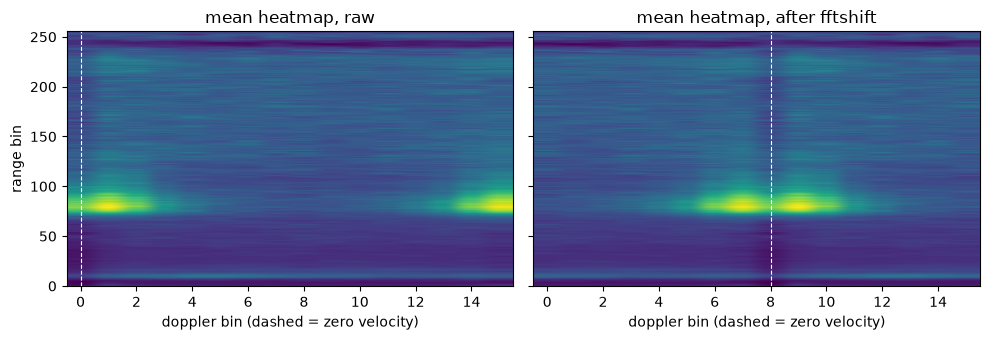

In [24]:
def preprocess_heatmap(heatmap):
    """Centre zero velocity in the doppler axis. Works on (range, doppler) or (frames, range, doppler)."""
    return np.fft.fftshift(np.asarray(heatmap, dtype=np.float32), axes=-1)


ok = rec_meta.heatmap_ok.to_numpy()
print(f"{(~ok).sum()} frames with a corrupted heatmap in this recording")
rec = rec.select(np.flatnonzero(ok))          # cheap: an index view, not a copy
rec_meta = rec_meta[ok]                       # keep the metadata aligned with the frames we keep
heat_raw = np.array(rec["heatmap"], dtype=np.float32)   # (frames, range_bins, doppler_bins)
heat = preprocess_heatmap(heat_raw)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for a, h, title, zero in zip(ax, [heat_raw, heat], ["raw", "after fftshift"], [0, heat.shape[2] // 2]):
    a.imshow(h.mean(axis=0), aspect="auto", origin="lower")
    a.axvline(zero, color="w", ls="--", lw=0.8)
    a.set(title=f"mean heatmap, {title}", xlabel="doppler bin (dashed = zero velocity)")
ax[0].set_ylabel("range bin")
plt.tight_layout()

## A single frame: camera, range-doppler heatmap and point cloud

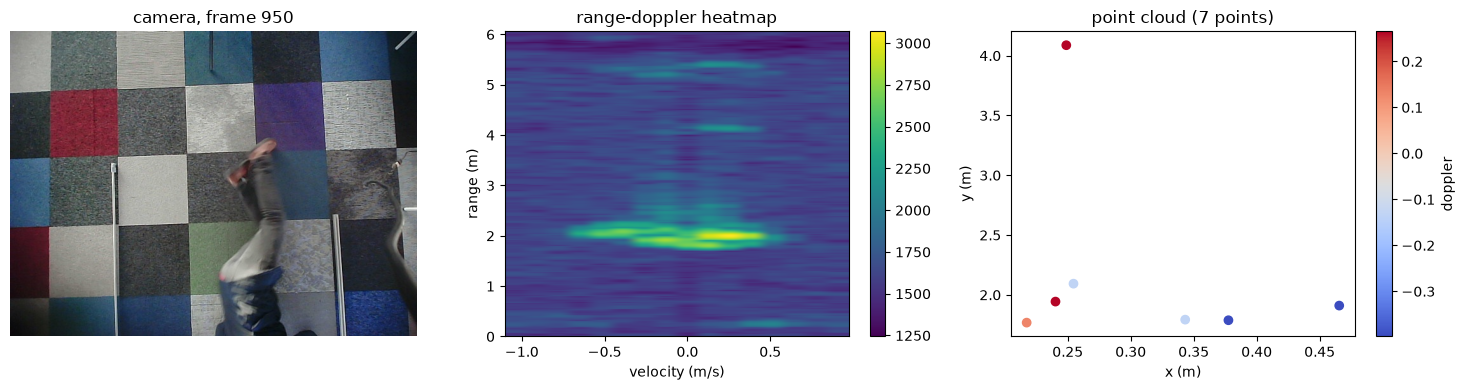

In [25]:
row = rec[len(rec) // 2]
heatmap = preprocess_heatmap(row["heatmap"])
cloud = np.asarray(row["pointcloud"]).reshape(-1, 7)  # x, y, z, doppler, snr, noise, track

range_max = heatmap.shape[0] * row["range_resolution_m"]
v_max, dv = row["max_velocity_m_s"], row["doppler_resolution_m_s"]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].imshow(row["image"])
ax[0].set_title(f"camera, frame {row['frame_idx']}")
ax[0].axis("off")

im = ax[1].imshow(heatmap, aspect="auto", origin="lower", extent=[-v_max - dv / 2, v_max - dv / 2, 0, range_max])  # bin 8 is centred on 0 m/s
ax[1].set(title="range-doppler heatmap", xlabel="velocity (m/s)", ylabel="range (m)")
fig.colorbar(im, ax=ax[1])

if len(cloud):
    sc = ax[2].scatter(cloud[:, 0], cloud[:, 1], c=cloud[:, 3], cmap="coolwarm")
    fig.colorbar(sc, ax=ax[2], label="doppler")
else:
    ax[2].text(0.5, 0.5, "no points", ha="center", va="center", transform=ax[2].transAxes)
ax[2].set(title=f"point cloud ({len(cloud)} points)", xlabel="x (m)", ylabel="y (m)")

plt.tight_layout()

## Over time

Sum the heatmap over the doppler axis to get energy per range bin per frame, and put a label track underneath.
`pose` is a string track, `state_labels` is the README's 0/1/2/3/99 encoding (moving/back/side/front/standing).

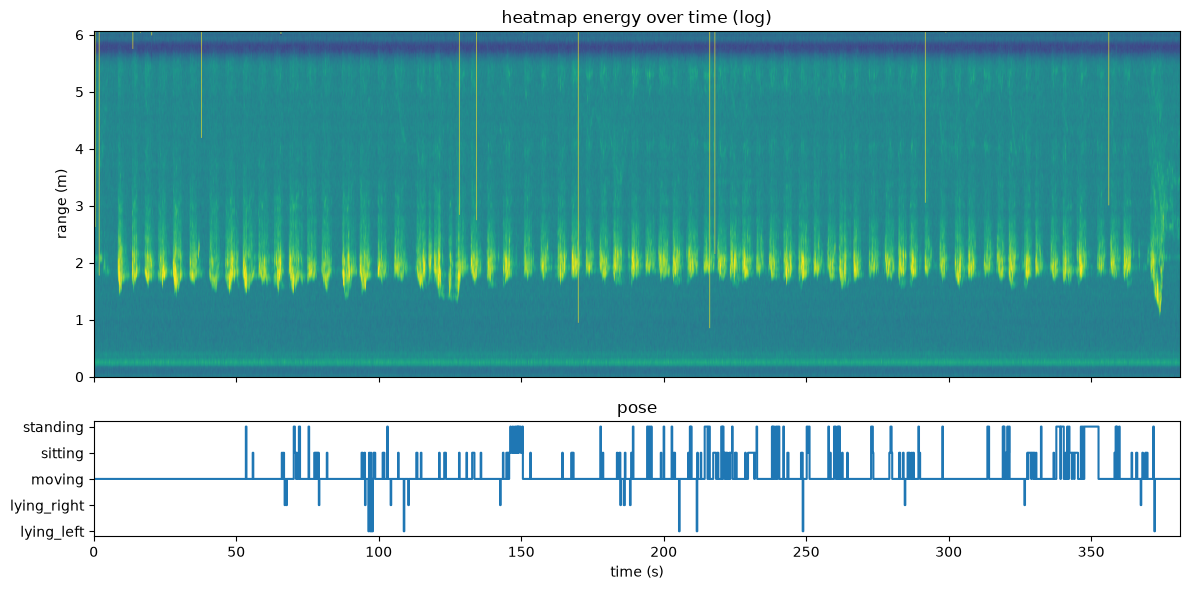

In [26]:
energy = heat.sum(axis=2).T                           # (range_bins, frames)
t = (rec_meta.timestamp - rec_meta.timestamp.iloc[0]).dt.total_seconds().to_numpy()
range_max = energy.shape[0] * rec_meta.range_resolution_m.iloc[0]

pose = rec_meta.label_pose.astype("category")

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

log_energy = np.log1p(energy)
# a few glitchy frames are much brighter than the rest, so clip the colour scale
ax[0].imshow(log_energy, aspect="auto", origin="lower", extent=[t[0], t[-1], 0, range_max],
             vmax=np.percentile(log_energy, 99.5))
ax[0].set(title="heatmap energy over time (log)", ylabel="range (m)")

ax[1].step(t, pose.cat.codes, where="post")
ax[1].set(yticks=range(len(pose.cat.categories)), yticklabels=pose.cat.categories, xlabel="time (s)", title="pose")

plt.tight_layout()

## All annotations at once

Pick a recording to see everything we know about it on one time axis: the range-energy map, total heatmap energy
and point count, then one strip per label track (the hand-labelled `person_present` first). Gaps in a strip mean
that track has no label there; tracks with no labels at all in the recording are listed in the title.
`person_present` needs a rebuild of the dataset after annotating presence; until then it is derived from
`data/processed/presence_events.csv`.

In [27]:
import functools
import shutil
import subprocess
from io import BytesIO

import ipywidgets as w
from IPython.display import Video, display

PRESENCE_EVENTS = repo / "data/processed/presence_events.csv"
STATE_NAMES = {0: "moving", 1: "back", 2: "side", 3: "front", 99: "standing"}  # README encoding of state_labels
STATE_ORDER = list(STATE_NAMES.values())
TRACKS = ["person_present"] + [c for c in label_cols if c != "label_orientation"]  # orientation is empty everywhere


def presence_from_events(rec_name, n):
    """Per-frame presence from presence_events.csv (same rule as data.extract), or None if unannotated."""
    if not PRESENCE_EVENTS.exists():
        return None
    ev = pd.read_csv(PRESENCE_EVENTS)
    ev = ev[ev.recording == rec_name].sort_values("frame_idx")
    if ev.empty:
        return None
    flags, state, last = np.zeros(n, dtype=object), False, 0
    for frame, event in zip(ev.frame_idx, ev.event):
        flags[last:frame] = state
        state, last = event == "enter", int(frame)
    flags[last:] = state
    return pd.Series(flags)


@functools.lru_cache(maxsize=4)
def recording_video(rec_name, width=240):
    """The camera frames of a recording as a small H.264 mp4 (bytes), at the recording's real frame rate.

    Needs ffmpeg on the PATH; the frames are piped to it as raw RGB.
    """
    if shutil.which("ffmpeg") is None:
        raise RuntimeError("ffmpeg not found; install it to play the video")
    m = meta[meta.recording == rec_name]
    start = m.index.min()
    secs = (m.timestamp.iloc[-1] - m.timestamp.iloc[0]).total_seconds()
    fps = (len(m) - 1) / secs
    first = ds[int(start)]["image"]
    size = (width, int(first.height * width / first.width) // 2 * 2)  # even height for yuv420p
    ffmpeg = subprocess.Popen(
        ["ffmpeg", "-loglevel", "error", "-y", "-f", "rawvideo", "-pix_fmt", "rgb24", "-s", f"{size[0]}x{size[1]}",
         "-r", f"{fps:.3f}", "-i", "-", "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "30",
         "-movflags", "frag_keyframe+empty_moov", "-f", "mp4", "-"],
        stdin=subprocess.PIPE, stdout=subprocess.PIPE,
    )

    def feed():
        blank = np.zeros((size[1], size[0], 3), np.uint8)
        for im in ds.select(range(start, start + len(m)))["image"]:
            frame = np.asarray(im.convert("RGB").resize(size)) if im is not None else blank
            ffmpeg.stdin.write(frame.tobytes())
        ffmpeg.stdin.close()

    import threading  # write in a thread so reading stdout can't deadlock on a full pipe
    threading.Thread(target=feed, daemon=True).start()
    data = ffmpeg.stdout.read()
    ffmpeg.wait()
    return data


def overview(rec_name):
    m = meta[meta.recording == rec_name].reset_index(drop=True)
    start = meta.index[meta.recording == rec_name].min()
    ok = m.heatmap_ok.to_numpy()
    t = (m.timestamp - m.timestamp.iloc[0]).dt.total_seconds().to_numpy()

    # energy per range bin per frame; frames with a corrupted heatmap stay NaN
    heat_ok = np.array(ds.select(start + np.flatnonzero(ok))["heatmap"], dtype=np.float32)
    energy = np.full((heat_ok.shape[1], len(m)), np.nan, dtype=np.float32)
    energy[:, ok] = heat_ok.sum(axis=2).T
    total = np.nansum(energy, axis=0)
    total[~ok] = np.nan
    range_max = energy.shape[0] * m.range_resolution_m.iloc[0]

    cols = {name: (m[name] if name in m else presence_from_events(rec_name, len(m))) for name in TRACKS}
    present = {k: s for k, s in cols.items() if s is not None and s.notna().any()}
    missing = [k.removeprefix("label_") for k in TRACKS if k not in present]

    fig, ax = plt.subplots(
        2 + len(present), 1, figsize=(13, 3.5 + 1.0 * len(present)), sharex=True,
        gridspec_kw={"height_ratios": [3, 1.5] + [1.2] * len(present)},
    )
    log_energy = np.log1p(energy)
    ax[0].imshow(log_energy, aspect="auto", origin="lower", extent=[t[0], t[-1], 0, range_max],
                 vmax=np.nanpercentile(log_energy, 99.5))
    ax[0].set(ylabel="range (m)", title="heatmap energy over time (log)")

    ax[1].plot(t, total, lw=0.8, color="C0")
    ax[1].set(ylabel="total energy")
    ax[1].set_yscale("log")
    twin = ax[1].twinx()
    twin.plot(t, m.n_points, lw=0.8, color="C1", alpha=0.7)
    twin.set(ylabel="points", ylim=(0, None))
    twin.yaxis.label.set_color("C1")

    for a, (name, s) in zip(ax[2:], present.items()):
        if name == "label_state_labels":
            s = s.map(STATE_NAMES)  # NaN stays NaN
        values = s.astype(object).where(s.notna(), None)
        cats = sorted({str(v) for v in values.dropna()},
                      key=lambda c: STATE_ORDER.index(c) if name == "label_state_labels" else (len(c), c))
        code = values.map(lambda v: cats.index(str(v)) if v is not None else np.nan).astype(float)
        # step the line only inside labelled runs; NaN leaves a gap
        a.step(t, code, where="post", color="k", lw=1.5)
        a.set_yticks(range(len(cats)), cats, fontsize=7)
        a.set_ylim(-0.6, len(cats) - 0.4)
        a.set_ylabel(name.removeprefix("label_"), rotation=0, ha="right", va="center")
        a.grid(axis="y", alpha=0.3)
    ax[-1].set_xlabel("time (s)")

    person = m.person.iloc[0]
    fig.suptitle(f"{rec_name}  |  person: {person}  |  room: {m.room.iloc[0]}  |  {len(m)} frames"
                 + (f"\nno labels: {', '.join(missing)}" if missing else ""), y=0.995)
    plt.tight_layout()
    plt.show()
    display(Video(data=recording_video(rec_name), embed=True, mimetype="video/mp4", html_attributes="controls loop"))


w.interact(overview, rec_name=w.Dropdown(options=sorted(meta.recording.unique()), value=REC, description="Recording",
                                         layout=w.Layout(width="520px"), style={"description_width": "80px"}));

interactive(children=(Dropdown(description='Recording', index=2, layout=Layout(width='520px'), options=('2311_…

## Label distributions

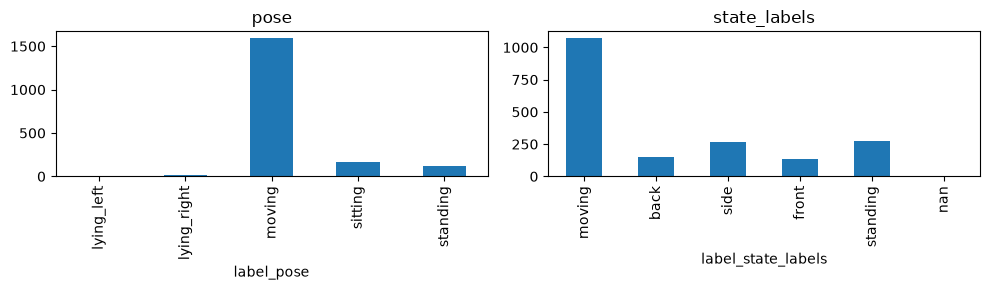

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, track in zip(ax, ["pose", "state_labels"]):
    labels = rec_meta[f"label_{track}"]
    if track == "state_labels":
        labels = labels.map(STATE_NAMES)  # defined in the "All annotations at once" cell
        counts = labels.value_counts(dropna=False).reindex([*STATE_ORDER, np.nan], fill_value=0)
    else:
        counts = labels.value_counts(dropna=False).sort_index()
    counts.plot.bar(ax=a, title=track)
plt.tight_layout()